# Milestone 1 – Data: source, exploration, preparation

This notebook covers the data part of Milestone 1:

1. **Data source** and how it is downloaded
2. **Data exploration and visualization**
3. **Preparing the data** for training
4. **Final output:** training, validation and test inputs (`X`) and outputs (`y`)

Training and evaluation are in `01_reproduce.ipynb`. Both notebooks use the same functions from
`src/reproduce.py`, so the data shown here is exactly what the models are trained on.

Runs locally or on Colab. The first run downloads about 80 MB per subject.

In [1]:
import os, sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not os.path.exists('/content/Deep_Learning_Project'):
        !git clone -q https://github.com/Semih2341/Deep_Learning_Project.git /content/Deep_Learning_Project
    %cd /content/Deep_Learning_Project
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

# Where MOABB caches the dataset (None = MNE default, ~/mne_data)
DATA_DIR = None
if not IN_COLAB and os.path.exists('../mne_data'):
    DATA_DIR = '../mne_data'

sys.path.insert(0, 'src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
mne.set_log_level('ERROR')
import reproduce as R
import prepare_data as P
R.set_data_dir(DATA_DIR)

## 1. Data source and download

**Dataset:** BCI Competition IV, dataset 2a (Graz University of Technology; Brunner et al., 2008),
distributed through the [BNCI Horizon 2020 database](https://bnci-horizon-2020.eu/database/data-sets)
as *001-2014*. In [MOABB](https://moabb.neurotechx.com) it is called **`BNCI2014_001`**.

**Download:** we do not download files by hand. `braindecode.datasets.MOABBDataset` asks MOABB
for the subject, and MOABB downloads the original `.mat` files from the BNCI server on first use,
caches them in the MNE data folder (`MNE_DATA`, or `--data-dir` / Google Drive on Colab) and returns
MNE `Raw` objects. Later runs read the files from the cache. The BNCI server is sometimes down, so
`reproduce.load_dataset` retries the download up to 5 times.

**Content:**
- 9 subjects, each recorded in **2 sessions on different days** (`0train`, `1test`)
- each session has **6 runs × 48 trials = 288 trials**, 72 per class
- 4 imagined movements: **left hand, right hand, feet, tongue**
- 22 EEG channels + 3 EOG channels, sampled at **250 Hz**
- trial: fixation cross, cue at t = 2 s, motor imagery until t = 6 s. Each event marks the cue, and the imagery lasts **4 s**.

In [2]:
dataset = R.load_dataset(3)          # downloads on first use, then reads from the cache
print(dataset.description)
raw = dataset.datasets[0].raw
print(f"\nsampling rate: {raw.info['sfreq']} Hz, duration of one run: {raw.times[-1]:.0f} s")
print('channels:', raw.ch_names)

    subject session run
0         3  0train   0
1         3  0train   1
2         3  0train   2
3         3  0train   3
4         3  0train   4
5         3  0train   5
6         3   1test   0
7         3   1test   1
8         3   1test   2
9         3   1test   3
10        3   1test   4
11        3   1test   5

sampling rate: 250.0 Hz, duration of one run: 387 s
channels: ['Fz', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P1', 'Pz', 'P2', 'POz', 'EOG1', 'EOG2', 'EOG3', 'STI']


## 2. Data exploration and visualization

### 2.1 Trials per class, subject and session

In [3]:
rows = []
for s in R.ALL_SUBJECTS:
    ds = R.load_dataset(s)
    for d, (_, desc) in zip(ds.datasets, ds.description.iterrows()):
        for label in d.raw.annotations.description:
            rows.append({'subject': s, 'session': desc['session'], 'class': label})
counts = pd.DataFrame(rows).pivot_table(index=['subject', 'session'], columns='class',
                                       aggfunc='size', fill_value=0)
counts['total'] = counts.sum(axis=1)
counts

class            feet  left_hand  right_hand  tongue  total
subject session                                            
1       0train     72         72          72      72    288
        1test      72         72          72      72    288
2       0train     72         72          72      72    288
        1test      72         72          72      72    288
3       0train     72         72          72      72    288
        1test      72         72          72      72    288
4       0train     72         72          72      72    288
        1test      72         72          72      72    288
5       0train     72         72          72      72    288
        1test      72         72          72      72    288
6       0train     72         72          72      72    288
        1test      72         72          72      72    288
7       0train     72         72          72      72    288
        1test      72         72          72      72    288
8       0train     72         72          72      72    288
        1test      72         72          72      72    288
9       0train     72         72          72      72    288
        1test      72         72          72      72    288

Every subject has 72 trials per class in each session (288 per session). The classes are perfectly
**balanced**, so plain accuracy is a fair metric and chance level is 25 %. In total there are
9 × 2 × 288 = 5184 trials.

### 2.2 Electrode positions

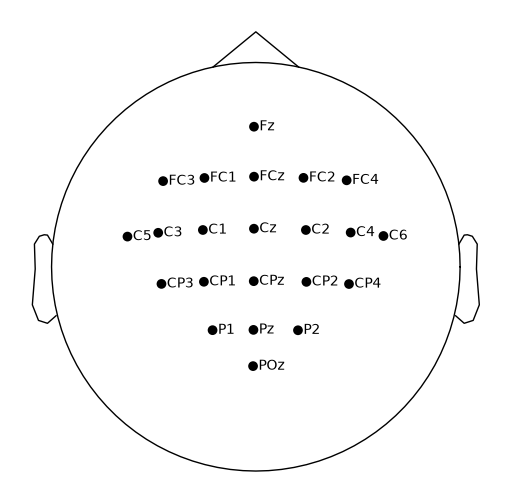

In [4]:
eeg = raw.copy().pick('eeg')
try:
    eeg.set_montage('standard_1005', on_missing='ignore')
    fig = eeg.plot_sensors(show_names=True, show=False)
    fig.set_size_inches(5, 5)
    plt.show()
except Exception as e:
    print('montage plot not available:', e)

The 22 electrodes cover the sensorimotor cortex. **C3** lies over the left motor cortex, which
controls the right hand, and **C4** over the right motor cortex (left hand). **Cz** lies over the foot area.

### 2.3 One raw trial

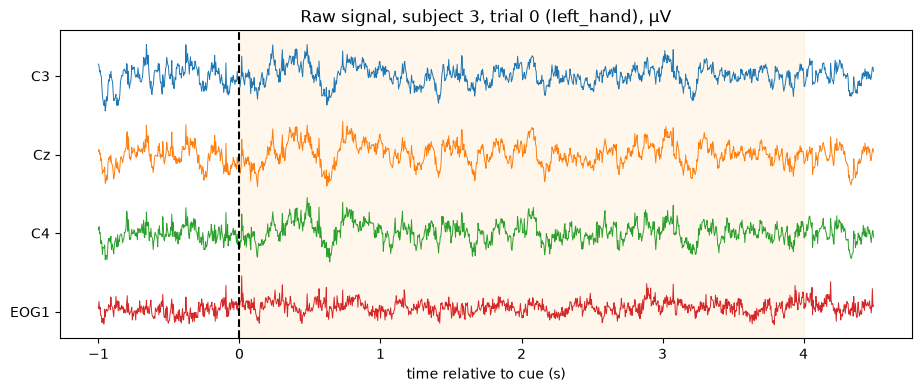

In [5]:
onsets = raw.annotations.onset
labels = raw.annotations.description
i = int(np.where(labels == 'left_hand')[0][0])
sf = raw.info['sfreq']
start, stop = int((onsets[i] - 1.0) * sf), int((onsets[i] + 4.5) * sf)
picks = ['C3', 'Cz', 'C4', 'EOG1']
data = raw.get_data(picks=picks, start=start, stop=stop) * 1e6
t = np.arange(data.shape[1]) / sf - 1.0

fig, ax = plt.subplots(figsize=(11, 4))
for k, (ch, sig) in enumerate(zip(picks, data)):
    ax.plot(t, sig - 60 * k, lw=0.7, label=ch)
ax.axvline(0, color='k', ls='--'); ax.axvspan(0, 4, color='orange', alpha=0.08)
ax.set_yticks([-60 * k for k in range(len(picks))], picks)
ax.set_xlabel('time relative to cue (s)'); ax.set_title(f'Raw signal, subject 3, trial {i} ({labels[i]}), µV')
plt.show()

The raw EEG is noisy and has slow drifts. The motor imagery is not visible by eye in a single trial,
which is why a learned model is needed. The EOG channel records eye movements; it is removed before training.

### 2.4 Frequency content per class (event-related desynchronization)

Imagining a hand movement lowers the **mu (8–13 Hz)** and **beta (13–30 Hz)** power over the opposite
hemisphere. Below we average the power spectrum of the imagery period (0.5–4 s after the cue) over
all training-session trials of subject 3.

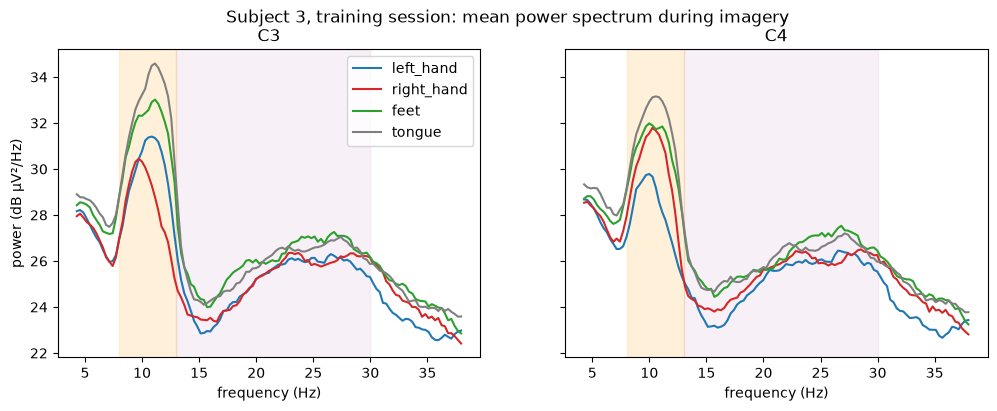

In [6]:
train_raws = [d.raw for d, (_, desc) in zip(dataset.datasets, dataset.description.iterrows())
              if desc['session'] == '0train']
raw_tr = mne.concatenate_raws([r.copy() for r in train_raws]).pick('eeg')
events, event_id = mne.events_from_annotations(raw_tr)
epochs = mne.Epochs(raw_tr, events, event_id, tmin=0.5, tmax=4.0, baseline=None, preload=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, ch in zip(axes, ['C3', 'C4']):
    for cls, color in [('left_hand', 'tab:blue'), ('right_hand', 'tab:red'),
                       ('feet', 'tab:green'), ('tongue', 'tab:gray')]:
        psd = epochs[cls].compute_psd(fmin=4, fmax=38, picks=[ch])
        p = 10 * np.log10(psd.get_data().mean(axis=0)[0] * 1e12)
        ax.plot(psd.freqs, p, color=color, label=cls)
    ax.axvspan(8, 13, color='orange', alpha=0.15); ax.axvspan(13, 30, color='purple', alpha=0.06)
    ax.set_title(ch); ax.set_xlabel('frequency (Hz)')
axes[0].set_ylabel('power (dB µV²/Hz)'); axes[0].legend()
plt.suptitle('Subject 3, training session: mean power spectrum during imagery'); plt.show()

The mu band (orange) differs between the classes, and the difference is lateralized: hand imagery
reduces power over the opposite motor cortex (right hand at C3, left hand at C4). The ShallowConvNet
is designed to exploit this effect. Its temporal filters act as band-pass filters, and its squaring +
mean-pooling + log steps compute log band power, like the classic FBCSP method.

## 3. Preparing the data for training

The steps are the same as in the braindecode tutorial and are implemented in `src/reproduce.py`:

| Step | Why |
|---|---|
| keep the 22 EEG channels (drop EOG and stim) | EOG measures eye movements, not brain activity |
| volts → µV (×1e6) | numerically better scale for training |
| band-pass 4–38 Hz | removes slow drifts and high-frequency noise; keeps mu/beta |
| exponential moving standardization (factor 1e-3) | per-channel running z-score; removes scale differences between channels and over time, and can run online |
| cut trials from 0.5 s before the cue to the end of the imagery into windows of 1000 samples (4 s) | input size of the network |
| cropped decoding | each window gives 467 overlapping crop predictions (receptive field 534 samples), so each trial yields many training examples |

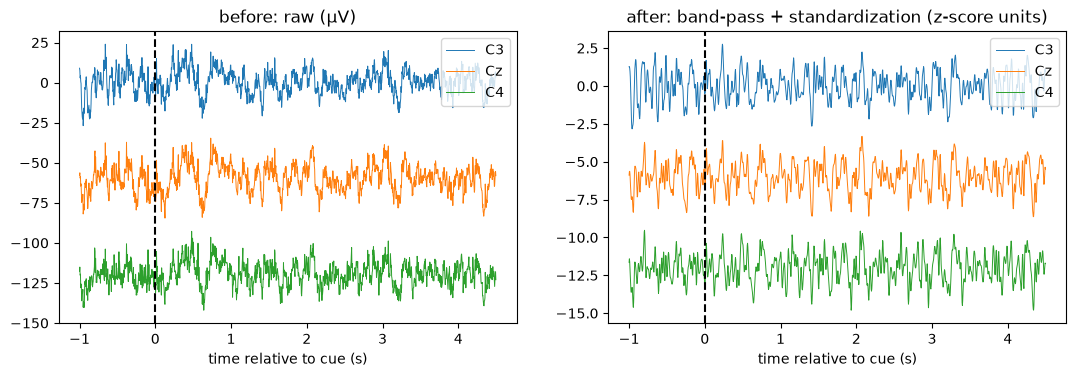

In [7]:
pre = R.preprocess_dataset(R.load_dataset(3))
raw_p = pre.datasets[0].raw
after = raw_p.get_data(picks=['C3', 'Cz', 'C4'], start=start, stop=stop)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, ch in enumerate(['C3', 'Cz', 'C4']):
    axes[0].plot(t, data[k] - 60 * k, lw=0.7, label=ch)
    axes[1].plot(t, after[k] - 6 * k, lw=0.7, label=ch)
axes[0].set_title('before: raw (µV)'); axes[1].set_title('after: band-pass + standardization (z-score units)')
for ax in axes:
    ax.axvline(0, color='k', ls='--'); ax.set_xlabel('time relative to cue (s)'); ax.legend(loc='upper right')
plt.show()

## 4. Final output: training, validation and test sets

`src/prepare_data.py` builds the three sets for every subject (within-subject protocol):

| Split | Source | Trials | Used for |
|---|---|---|---|
| **train** | session `0train`, runs 0–4 | 240 | fitting the weights |
| **valid** | session `0train`, run 5 | 48 | model selection (epochs, hyperparameters) from Milestone 2 on |
| **test** | session `1test`, runs 0–5 | 288 | final evaluation only |

The validation set is a whole held-out run, so its crops never overlap training data. The test
session is recorded on a different day and is never used for any decision. Each trial gives
2 windows of 1000 samples. The input `X` has shape *(windows, 22 channels, 1000 samples)*, and the
output `y` is the class index (0 = feet, 1 = left hand, 2 = right hand, 3 = tongue).

In [8]:
splits, n_preds = P.prepare_subject(3)
table = pd.DataFrame({name: P.describe(s) for name, s in splits.items()}).T
print(f'crop predictions per window: {n_preds}')
table[['n_trials', 'n_windows', 'X_shape', 'y_shape', 'trials_per_class']]

crop predictions per window: 467


,n_trials,n_windows,X_shape,y_shape,trials_per_class
train,240,480,"[480, 22, 1000]",[480],"{'feet': 60, 'left_hand': 60, 'right_hand': 60..."
valid,48,96,"[96, 22, 1000]",[96],"{'feet': 12, 'left_hand': 12, 'right_hand': 12..."
test,288,576,"[576, 22, 1000]",[576],"{'feet': 72, 'left_hand': 72, 'right_hand': 72..."


In [9]:
X, y, window_ind = splits['train'][0]
print('one input  X:', X.shape, X.dtype, '(channels × samples)')
print('its output y:', y, '=', P.CLASS_NAMES[y])

Xv, yv = P.to_arrays(splits['valid'])
print('validation arrays:', Xv.shape, yv.shape, 'label counts:', np.bincount(yv))

one input  X: (22, 1000) float32 (channels × samples)
its output y: 1 = left_hand
validation arrays: (96, 22, 1000) (96,) label counts: [24 24 24 24]


### All subjects

`python src/prepare_data.py --subjects all` writes the same summary for all 9 subjects to
`results/data_splits.json`. Add `--save-npz <folder>` to also save the `X`/`y` arrays.

In [10]:
import json
s = json.load(open('results/data_splits.json'))
pd.DataFrame({
    subj: {f'{split} X': tuple(info[split]['X_shape']) for split in ['train', 'valid', 'test']}
    for subj, info in s['subjects'].items()
}).T

,train X,valid X,test X
1,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
2,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
3,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
4,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
5,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
6,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
7,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
8,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
9,"(480, 22, 1000)","(96, 22, 1000)","(576, 22, 1000)"
